# 3. Evaluating the model

The test split has not been touched until now. Three questions matter,
not two, and the third is arguably the point of this whole project:

1. **Is it accurate**, measured in a way that is not flattered by the
   class imbalance?
2. **Is its confidence honest?** The app shows a percentage to someone
   deciding whether an uploaded photo looks concerning, so an
   overconfident model is actively misleading, not merely inaccurate.
3. **When it is wrong about a malignant lesion, how is it wrong?**
   Calling a melanoma a basal cell carcinoma is a mistake about the
   subtype. Calling a melanoma a mole is a mistake that could get someone
   killed. Per-class accuracy treats those the same; this notebook does
   not.

In [1]:
import sys
from pathlib import Path


def find_repo_root(start: Path) -> Path:
    """Walk up from `start` until the repository layout is recognisable.

    Lets the notebook run from the repo root, from notebooks/, or from a
    Jupyter server started somewhere else entirely.
    """
    for candidate in (start, *start.parents):
        if (candidate / "config").is_dir() and (candidate / "src" / "skinlesion").is_dir():
            return candidate
    raise RuntimeError(f"could not locate the repository root from {start}")


REPO = find_repo_root(Path.cwd())
sys.path.insert(0, str(REPO / "src"))

CONFIG = REPO / "config" / "smoke.yaml"   # swap for config/default.yaml for the full 10,015-image run
print(f"repository root: {REPO}")

repository root: /Users/cherylt/projects/skin-lesion-id


In [2]:
import numpy as np
import torch
from torch.utils.data import DataLoader

from skinlesion.config import load_config
from skinlesion.data.datasets import LesionImageDataset, build_eval_transform
from skinlesion.data.metadata import DIAGNOSIS_NAMES, drop_sparse_classes, read_metadata
from skinlesion.data.splits import assert_no_leakage, build_splits
from skinlesion.modelling.model import load_checkpoint, select_device

config = load_config(CONFIG)
records = read_metadata(
    REPO / config.paths.metadata_file,
    allowed_classes=config.data.classes,
    source_filter=config.data.source_filter,
)
records, _ = drop_sparse_classes(records, config.data.min_images_per_class)

split = build_splits(records, config.split)
assert_no_leakage(split)

device = select_device()
checkpoint_path = REPO / config.paths.artifacts_dir / "model.pt"
model, metadata = load_checkpoint(checkpoint_path, device)

images_dir = REPO / config.paths.images_dir
loader_kwargs = {"batch_size": config.training.batch_size, "num_workers": 0}

test_set = LesionImageDataset(
    split.test, images_dir, split.class_to_index, build_eval_transform(metadata.image_size),
)
val_set = LesionImageDataset(
    split.val, images_dir, split.class_to_index, build_eval_transform(metadata.image_size),
)
test_loader = DataLoader(test_set, shuffle=False, **loader_kwargs)
val_loader = DataLoader(val_set, shuffle=False, **loader_kwargs)

print(f"test images: {len(test_set)}")

test images: 333


In [3]:
def collect(loader):
    logits, labels = [], []
    with torch.no_grad():
        for images, targets in loader:
            logits.append(model(images.to(device)).cpu().numpy())
            labels.append(targets.numpy())
    return np.concatenate(logits), np.concatenate(labels)

test_logits, test_labels = collect(test_loader)
val_logits, val_labels = collect(val_loader)

## Accuracy

Top-1 is the strict measure. Top-3 matters for how a triage-support tool
would actually be used: a differential-diagnosis shortlist, not a single
forced answer. Macro-F1 weights every diagnosis equally regardless of how
common it is.

In [4]:
from skinlesion.evaluation.calibration import softmax
from skinlesion.evaluation.metrics import evaluate

probabilities = softmax(test_logits, temperature=metadata.temperature)
report = evaluate(
    probabilities, test_labels, split.class_names,
    top_k=config.evaluation.top_k, malignant_classes=config.evaluation.malignant_classes,
)

print(f"top-1 accuracy   {report.accuracy:.3f}")
print(f"top-{report.top_k} accuracy   {report.top_k_accuracy:.3f}")
print(f"macro F1         {report.macro_f1:.3f}")
print()
chance = 1 / len(split.class_names)
print(f"chance level ({len(split.class_names)} classes): {chance:.3f}")

top-1 accuracy   0.562
top-3 accuracy   0.916
macro F1         0.486

chance level (5 classes): 0.200


## The number that actually matters clinically

Of the test images that are truly malignant or pre-malignant (melanoma,
basal cell carcinoma or actinic keratosis), what fraction did the model
flag as such -- regardless of which specific one it guessed? A miss here
is a missed cancer, independent of which malignant subtype the model
thought it saw instead.

In [5]:
mr = report.malignant_recall
if mr is None:
    print("No malignant class had support in this test split.")
else:
    print(f"malignant classes tracked: {mr.malignant_classes}")
    print(f"malignant/pre-malignant lesions in test: {mr.support}")
    print(f"caught: {mr.support - mr.missed}   missed: {mr.missed}")
    print(f"malignant recall: {mr.recall:.3f}")

malignant classes tracked: ('mel', 'bcc', 'akiec')
malignant/pre-malignant lesions in test: 139
caught: 82   missed: 57
malignant recall: 0.590


## Which diagnoses does it struggle with?

In [6]:
import pandas as pd

per_class = pd.DataFrame([
    {"diagnosis": m.class_name, "name": DIAGNOSIS_NAMES[m.class_name], "support": m.support,
     "precision": m.precision, "recall": m.recall, "f1": m.f1}
    for m in report.per_class
]).sort_values("f1")

print(per_class.to_string(index=False, float_format="%.3f"))

diagnosis                                          name  support  precision  recall    f1
      mel                                      Melanoma       51      0.277   0.255 0.265
    akiec Actinic keratosis / intraepithelial carcinoma       44      0.409   0.409 0.409
      bkl                              Benign keratosis       73      0.483   0.397 0.436
      bcc                          Basal cell carcinoma       44      0.645   0.455 0.533
       nv                             Melanocytic nevus      121      0.709   0.884 0.787


correlation between support and F1: 0.80


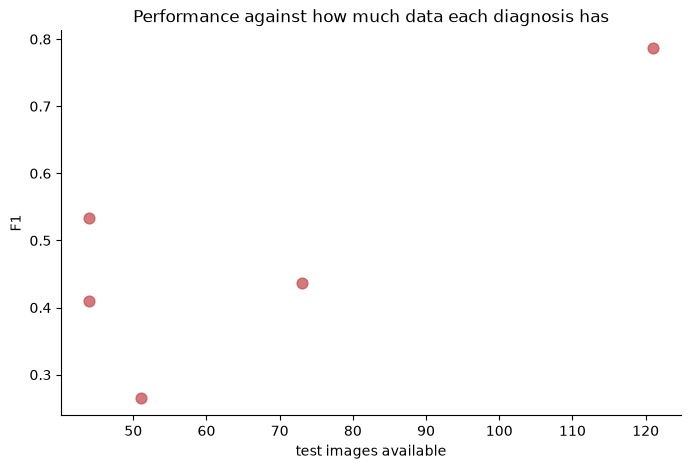

In [7]:
import matplotlib.pyplot as plt

if per_class["f1"].nunique() == 1:
    print(f"every diagnosis scored F1 {per_class['f1'].iloc[0]:.3f} on this test split, "
          "so support and F1 have no variance to correlate against each other")
else:
    ax = per_class.plot.scatter(
        x="support", y="f1", figsize=(8, 5), s=60, alpha=0.75, color="#C44E52"
    )
    ax.set_xlabel("test images available")
    ax.set_ylabel("F1")
    ax.set_title("Performance against how much data each diagnosis has")
    ax.spines[["top", "right"]].set_visible(False)

    correlation = per_class["support"].corr(per_class["f1"])
    print(f"correlation between support and F1: {correlation:.2f}")

## What gets confused with what

Confusions between visually similar diagnoses (two benign lesion types,
say) are a different kind of failure from a malignant lesion called
benign. malignant_recall above already isolates the second, clinically
load-bearing failure mode; this list shows the shape of the rest.

In [8]:
if not report.confusions:
    print("No misclassifications on this test split.")
else:
    for pair in report.confusions[:10]:
        flag = " (malignant -> benign)" if (
            pair.true_class in config.evaluation.malignant_classes
            and pair.predicted_class not in config.evaluation.malignant_classes
        ) else ""
        print(f"  {pair.count:>3}x  {pair.true_class} ({DIAGNOSIS_NAMES[pair.true_class]})"
              f"  ->  {pair.predicted_class} ({DIAGNOSIS_NAMES[pair.predicted_class]}){flag}")

   25x  mel (Melanoma)  ->  nv (Melanocytic nevus) (malignant -> benign)
   20x  bkl (Benign keratosis)  ->  mel (Melanoma)
   15x  akiec (Actinic keratosis / intraepithelial carcinoma)  ->  bkl (Benign keratosis) (malignant -> benign)
   11x  bcc (Basal cell carcinoma)  ->  akiec (Actinic keratosis / intraepithelial carcinoma)
   11x  bkl (Benign keratosis)  ->  akiec (Actinic keratosis / intraepithelial carcinoma)
   10x  nv (Melanocytic nevus)  ->  bkl (Benign keratosis)
    8x  bcc (Basal cell carcinoma)  ->  nv (Melanocytic nevus) (malignant -> benign)
    8x  bkl (Benign keratosis)  ->  nv (Melanocytic nevus)
    6x  mel (Melanoma)  ->  bkl (Benign keratosis) (malignant -> benign)
    5x  akiec (Actinic keratosis / intraepithelial carcinoma)  ->  mel (Melanoma)


## Calibration

A fine-tuned network typically reports 0.95 on predictions that are right
about 80 percent of the time. Temperature scaling fits one scalar on the
validation split to correct this. It cannot change which class ranks
highest, so accuracy is unaffected; only the reported confidence changes
-- which matters here because that confidence is what the abstain
threshold below actually acts on.

In [9]:
from skinlesion.evaluation.calibration import calibrate

before, after = calibrate(
    val_logits, val_labels, test_logits, test_labels,
    num_bins=config.evaluation.calibration_bins,
)

print(f"before scaling:  ECE {before.expected_calibration_error:.4f}  (T = 1.00)")
print(f"after scaling:   ECE {after.expected_calibration_error:.4f}  (T = {after.temperature:.3f})")
print()
change = before.expected_calibration_error - after.expected_calibration_error
direction = "underconfident" if not before.is_overconfident else "overconfident"
print(f"{'improvement' if change > 0 else 'regression'}: {change:+.4f}")
print(f"model was {direction} before scaling")

before scaling:  ECE 0.0934  (T = 1.00)
after scaling:   ECE 0.0515  (T = 1.290)

improvement: +0.0419
model was overconfident before scaling


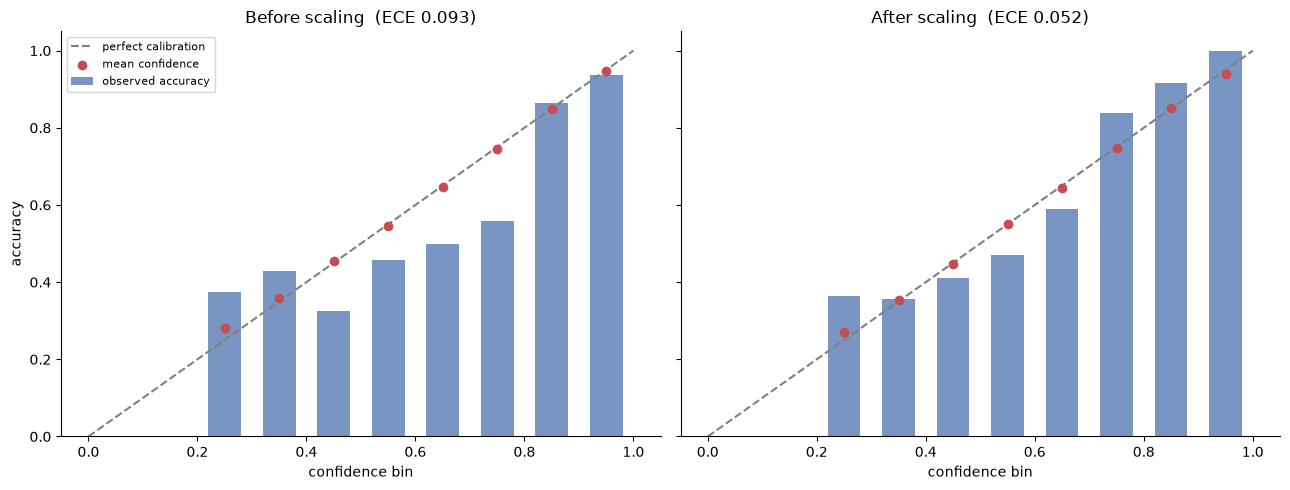

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, rep, title in zip(axes, (before, after), ("Before scaling", "After scaling")):
    populated = [b for b in rep.bins if b.count > 0]
    centres = [(b.lower + b.upper) / 2 for b in populated]

    ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect calibration")
    ax.bar(centres, [b.accuracy for b in populated], width=0.06, alpha=0.75,
           color="#4C72B0", label="observed accuracy")
    ax.scatter(centres, [b.mean_confidence for b in populated], color="#C44E52",
               zorder=3, label="mean confidence")
    ax.set_xlabel("confidence bin")
    ax.set_title(f"{title}  (ECE {rep.expected_calibration_error:.3f})")
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("accuracy")
axes[0].legend(fontsize=8)
fig.tight_layout()

## The abstain threshold

The app declines to name a diagnosis below a confidence threshold. That
trade is worth quantifying here specifically: how much accuracy is gained
on the answers it does give, what fraction of images does it decline, and
-- the question that matters more than either -- does raising the
threshold also raise malignant recall on the images it does answer for?

In [11]:
from skinlesion.evaluation.metrics import malignant_recall as compute_malignant_recall

confidences = probabilities.max(axis=1)
predictions = probabilities.argmax(axis=1)
correct = predictions == test_labels

print(f"{'threshold':>10} {'answered':>10} {'accuracy':>10} {'malignant recall':>18}")
for threshold in (0.0, 0.3, config.evaluation.abstain_threshold, 0.6, 0.75, 0.9):
    answered = confidences >= threshold
    rate = answered.mean()
    accuracy = correct[answered].mean() if answered.any() else float("nan")
    mr_at_threshold = compute_malignant_recall(
        predictions[answered], test_labels[answered], split.class_names,
        config.evaluation.malignant_classes,
    )
    mr_text = f"{mr_at_threshold.recall:.3f}" if mr_at_threshold else "n/a"
    marker = "  <- configured" if threshold == config.evaluation.abstain_threshold else ""
    print(f"{threshold:>10.2f} {rate:>10.1%} {accuracy:>10.3f} {mr_text:>18}{marker}")

 threshold   answered   accuracy   malignant recall
      0.00     100.0%      0.562              0.590
      0.30      96.7%      0.568              0.586
      0.50      54.1%      0.711              0.585  <- configured
      0.60      38.7%      0.806              0.583
      0.75      20.4%      0.926              0.800
      0.90       5.1%      1.000              1.000


## Summary

**Accuracy.** Top-1 0.562, top-3 0.916, macro-F1 0.486 on 333 held-out
test images across five diagnoses (chance is 0.20). The gap between
top-1 and top-3 is the most useful number here: the correct diagnosis is
in the shortlist far more often than it is the single best guess, which
matters for how a triage-support tool would actually be used -- a
differential list a clinician reviews, not a forced single answer this
tool commits to.

**The number that matters most: malignant recall is 0.590.** Of 139
malignant or pre-malignant lesions in the test set (melanoma, basal cell
carcinoma, actinic keratosis), the model correctly flagged 82 and missed
57. That is not a good number, and it should not be dressed up as one.
Melanoma specifically is the weakest class by a wide margin (F1 0.265,
recall 0.255) -- the model catches roughly one in four melanomas outright,
though top-3 accuracy is much higher, so most missed melanomas still
appear somewhere in the shortlist rather than being ranked far away. The
single most frequent mistake in the whole confusion table is exactly the
dangerous one: melanoma called an ordinary mole, 25 times.

**The abstain threshold does not fix this, and that is worth stating
plainly rather than hiding.** Raising the threshold from 0.00 to 0.60
takes overall accuracy from 0.562 to 0.806 -- a real improvement -- while
malignant recall barely moves, from 0.590 to 0.583. The model's
confidence and its correctness on the malignant/benign question are not
well aligned at moderate thresholds: it can be highly confident about a
melanoma and still call it benign. Malignant recall only recovers, to
0.80 and then 1.00, at thresholds so high that coverage collapses to 20%
and then 5% of images. As configured (threshold 0.50), the abstain
mechanism mostly improves how often the model is willing to name *a*
diagnosis; it does not, on this evidence, meaningfully protect against
the specific failure that matters clinically. A production version of
this idea would need a threshold -- or a separate decision rule -- tuned
specifically against malignant recall, not overall accuracy.

**Calibration.** Expected calibration error dropped from 0.093 to 0.052
after temperature scaling (T = 1.290) -- the model was overconfident
before scaling, the usual direction, unlike the underconfident pattern
seen on the nudibranch smoke runs. The correction is real but calibration
alone does not address the malignant-recall problem above; a
well-calibrated model can still be systematically wrong about one
specific, important class.

**Why this differs from the nudibranch result.** The frozen-DINOv2 recipe
that reached 1.000 accuracy on nudibranch species reaches 0.562 here on
the same kind of budget (a few thousand images, a linear head, no
fine-tuning). Support correlates strongly with F1 in this test set
(r = 0.80, noticeably stronger than nudibranch's 0.52), which is
consistent with a real, harder visual problem rather than a bug: melanoma
and basal cell carcinoma are diagnoses that trained dermatologists get
wrong at meaningful rates from an image alone, and 2,259 training images
is genuinely little data for five classes with this much visual overlap.
This is the honest limit of the frugal-AI approach for this task at this
scale, not evidence it was the wrong thing to try.

**Open limitations, unchanged by any of the above.**

- **Closed-set.** No way to say "this is not one of the five things I
  know." Anything else is forced into the nearest known class.
- **Dermatoscope-only.** Trained and evaluated on dermatoscopic images,
  not ordinary phone photos, which look meaningfully different.
- **Demographic scope.** HAM10000, and this subset within it, is not
  documented by Fitzpatrick skin type, and dermoscopy archives are known
  to skew toward lighter skin tones. Performance on darker skin is
  untested and should not be assumed to match the numbers above.
- **Not a diagnostic device.** Everything in this notebook is a machine
  learning exercise on a research dataset. It has not been clinically
  validated, and nothing here should inform a real decision about a real
  lesion.